In [1]:
import pickle
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.autograd import Function
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import mutual_info_classif
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import (
    classification_report, balanced_accuracy_score,
    roc_auc_score, f1_score, confusion_matrix,
    matthews_corrcoef, cohen_kappa_score
)
import seaborn as sns
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import classification_report, f1_score, confusion_matrix
from imblearn.over_sampling import SMOTE
import numpy as np

In [2]:
with open('/home/matildxi/Secretária/Documentos/Tese/DANN/wesad/processed_data_sequences.pkl', 'rb') as f:
    data = pickle.load(f)

X_seq      = data['X_seq']
y_seq      = data['y_seq']
groups_seq = data['groups_seq']

le = LabelEncoder()
domain_labels = le.fit_transform(groups_seq)

In [3]:
print(X_seq.shape)
print(y_seq.shape)
print(np.unique(y_seq))

(27543, 16, 60)
(27543,)
[0 1]


In [4]:
selected_idx = [0, 5, 6, 7, 8] # Equivalente a acc_wrist + hr + ibi + rmssd + sdnn (wrist/BVP)
X_seq = X_seq[:, selected_idx, :]  

In [5]:
class TransformerClassifier(nn.Module):
    def __init__(self, in_channels=5, seq_len=60, num_classes=2,
                 d_model=128, nhead=4, num_layers=2, dropout=0.2):
        super().__init__()
        # projeção dos canais para d_model
        self.input_proj = nn.Linear(in_channels, d_model)
        
        # positional encoding simples
        self.pos_embedding = nn.Parameter(torch.randn(1, seq_len, d_model))
        
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=256,
            dropout=dropout,
            batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        
        self.classifier = nn.Sequential(
            nn.Linear(d_model, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        x = x.permute(0, 2, 1)          # (batch, 60, 16)
        x = self.input_proj(x)           # (batch, 60, d_model)
        x = x + self.pos_embedding       # adiciona positional encoding
        x = self.transformer(x)          # (batch, 60, d_model)
        x = x.mean(dim=1)               # mean pooling sobre timesteps
        return self.classifier(x)

In [6]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
logo   = LeaveOneGroupOut()

all_preds  = []
all_labels = []
fold_f1s   = []

for fold, (train_idx, test_idx) in enumerate(logo.split(X_seq, y_seq, groups=groups_seq)):
    subject_id = groups_seq[test_idx[0]]
    print(f"Fold {fold+1:2d} | Test subject: {subject_id}")

    X_train_raw = X_seq[train_idx]
    y_train_raw = y_seq[train_idx]
    X_test_raw  = X_seq[test_idx]
    y_test_raw  = y_seq[test_idx]

    # normalização dentro do fold
    n_train, C, T = X_train_raw.shape
    X_train_2d = X_train_raw.reshape(n_train, C * T)
    X_test_2d  = X_test_raw.reshape(len(X_test_raw), C * T)
    scaler = StandardScaler()
    X_train_2d = scaler.fit_transform(X_train_2d)
    X_test_2d  = scaler.transform(X_test_2d)
    X_train_raw = X_train_2d.reshape(n_train, C, T)
    X_test_raw  = X_test_2d.reshape(len(X_test_raw), C, T)

    # SMOTE
    X_flat = X_train_raw.reshape(n_train, C * T)
    smote = SMOTE(random_state=42)
    X_res, y_res = smote.fit_resample(X_flat, y_train_raw)
    X_res = X_res.reshape(-1, C, T)

    X_tr = torch.tensor(X_res,      dtype=torch.float32)
    y_tr = torch.tensor(y_res,      dtype=torch.long)
    X_te = torch.tensor(X_test_raw, dtype=torch.float32)
    y_te = torch.tensor(y_test_raw, dtype=torch.long)

    train_loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=64, shuffle=True)
    test_loader  = DataLoader(TensorDataset(X_te, y_te), batch_size=64)

    model     = TransformerClassifier(in_channels=5).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.5)

    EPOCHS = 50
    best_f1 = 0
    best_state = None
    patience = 10
    no_improve = 0

    for epoch in range(EPOCHS):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            criterion(model(xb), yb).backward()
            optimizer.step()
        scheduler.step()

        model.eval()
        ep_preds = []
        with torch.no_grad():
            for xb, _ in test_loader:
                ep_preds.extend(model(xb.to(device)).argmax(1).cpu().numpy())
        ep_f1 = f1_score(y_te.numpy(), ep_preds, average='macro')

        if ep_f1 > best_f1:
            best_f1 = ep_f1
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            no_improve = 0
        else:
            no_improve += 1
            if no_improve >= patience:
                break

    model.load_state_dict(best_state)
    model.eval()
    fold_preds = []
    with torch.no_grad():
        for xb, _ in test_loader:
            fold_preds.extend(model(xb.to(device)).argmax(1).cpu().numpy())

    f1 = f1_score(y_te.numpy(), fold_preds, average='macro')
    fold_f1s.append(f1)
    all_preds.extend(fold_preds)
    all_labels.extend(y_te.numpy())
    print(f"  Macro F1: {f1:.4f}\n")

Fold  1 | Test subject: S10
  Macro F1: 0.5926

Fold  2 | Test subject: S11
  Macro F1: 0.6320

Fold  3 | Test subject: S13
  Macro F1: 0.5963

Fold  4 | Test subject: S14
  Macro F1: 0.6893

Fold  5 | Test subject: S15
  Macro F1: 0.6107

Fold  6 | Test subject: S16
  Macro F1: 0.6733

Fold  7 | Test subject: S17
  Macro F1: 0.6858

Fold  8 | Test subject: S2
  Macro F1: 0.6965

Fold  9 | Test subject: S3
  Macro F1: 0.6597

Fold 10 | Test subject: S4
  Macro F1: 0.7369

Fold 11 | Test subject: S5
  Macro F1: 0.8145

Fold 12 | Test subject: S6
  Macro F1: 0.6258

Fold 13 | Test subject: S7
  Macro F1: 0.6728

Fold 14 | Test subject: S8
  Macro F1: 0.7690

Fold 15 | Test subject: S9
  Macro F1: 0.6670



Estatísticas FINAIS - TRANSFORMER + SMOTE
              precision    recall  f1-score   support

    baseline       0.78      0.73      0.75     17577
      stress       0.57      0.63      0.60      9966

    accuracy                           0.70     27543
   macro avg       0.68      0.68      0.68     27543
weighted avg       0.70      0.70      0.70     27543

Balanced Accuracy:        0.683
Macro F1 médio por fold:  0.675
Desvio Padrão F1 (LOSO):  0.060
Matthews Corr. Coef.:     0.359
Cohen's Kappa:            0.357

F1 por fold:
  Sujeito 01: 0.593
  Sujeito 02: 0.632
  Sujeito 03: 0.596
  Sujeito 04: 0.689
  Sujeito 05: 0.611
  Sujeito 06: 0.673
  Sujeito 07: 0.686
  Sujeito 08: 0.697
  Sujeito 09: 0.660
  Sujeito 10: 0.737
  Sujeito 11: 0.814
  Sujeito 12: 0.626
  Sujeito 13: 0.673
  Sujeito 14: 0.769
  Sujeito 15: 0.667


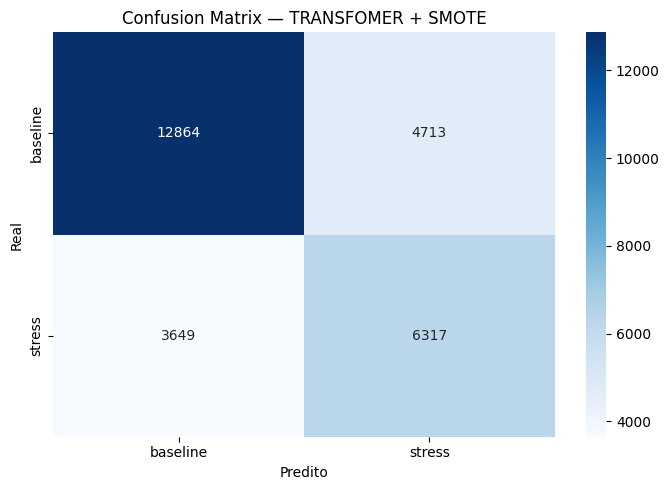

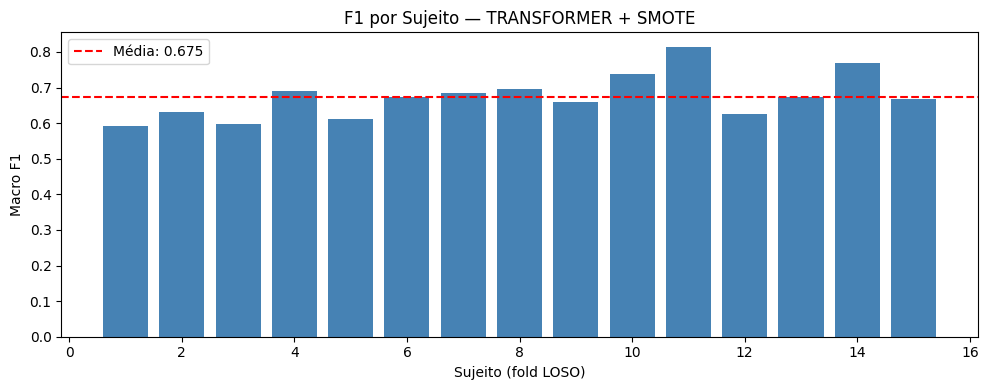

In [7]:
all_labels = np.array(all_labels)
all_preds  = np.array(all_preds)

print("=" * 50)
print("Estatísticas FINAIS - TRANSFORMER + SMOTE")
print("=" * 50)
print(classification_report(all_labels, all_preds,
                             target_names=['baseline', 'stress'],
                             zero_division=0))
print(f"Balanced Accuracy:        {balanced_accuracy_score(all_labels, all_preds):.3f}")
print(f"Macro F1 médio por fold:  {np.mean(fold_f1s):.3f}")
print(f"Desvio Padrão F1 (LOSO):  {np.std(fold_f1s):.3f}")
print(f"Matthews Corr. Coef.:     {matthews_corrcoef(all_labels, all_preds):.3f}")
print(f"Cohen's Kappa:            {cohen_kappa_score(all_labels, all_preds):.3f}")

print(f"\nF1 por fold:")
subjects = np.unique(groups_seq)
for i, f1 in enumerate(fold_f1s):
    print(f"  Sujeito {i+1:02d}: {f1:.3f}")

# confusion matrix
plt.figure(figsize=(7, 5))
sns.heatmap(confusion_matrix(all_labels, all_preds),
            annot=True, fmt='d', cmap='Blues',
            xticklabels=['baseline', 'stress'],
            yticklabels=['baseline', 'stress'])
plt.title('Confusion Matrix — TRANSFOMER + SMOTE')
plt.ylabel('Real'); plt.xlabel('Predito')
plt.tight_layout()
plt.show()

# F1 por sujeito
plt.figure(figsize=(10, 4))
plt.bar(range(1, len(fold_f1s)+1), fold_f1s, color='steelblue')
plt.axhline(np.mean(fold_f1s), color='red', linestyle='--',
            label=f'Média: {np.mean(fold_f1s):.3f}')
plt.xlabel('Sujeito (fold LOSO)')
plt.ylabel('Macro F1')
plt.title('F1 por Sujeito — TRANSFORMER + SMOTE')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# F1 @ Youden-optimal threshold
from sklearn.metrics import roc_curve, f1_score
import numpy as np
_yt = np.array(y_test); _ys = np.array(y_score)
_fpr, _tpr, _thr = roc_curve(_yt, _ys)
_t_opt = float(_thr[np.argmax(_tpr - _fpr)])
_f1opt = f1_score(_yt, (_ys >= _t_opt).astype(int), average='macro', zero_division=0)
print(f'F1@opt : {_f1opt:.3f}  (threshold={_t_opt:.3f})')